# 08. Advanced families and hyperparameter tuning

Besides the residual hybrid `ŷ = b + α·r̂`, the search can try three structures:

| Family | Strategy | Idea |
|---|---|---|
| `residual` | `residual_multistage` | correction of the correction: each stage learns the error of the previous model (up to 3) |
| `decomposition` | `decomposition` | `y = smooth + volatile`; the base forecasts the smooth part and a corrector the volatile one. `ma`: **causal** moving average with the window chosen by kurtosis; `stl`: variant A only |
| `combination` | `fixed_combination` | weighted mean of two bases; equal weights or by the inverse of the out-of-sample error on the training data |

All of them follow the same causality rules: nothing after the origin enters the fitting, the windows or the weights. The incremental selection treats each one as one more family: it only gets in if it beats the current champion by the protocol's rule.

At the end, `tune_model` tunes the hyperparameters of a base **on `V_search` only**.

In [1]:
import autohybts

print("AutoHybTS", autohybts.__version__)

AutoHybTS 1.0.0rc4


## 1. Experiment

In [2]:
from autohybts import AutoHybridExperiment
from autohybts.datasets import get_data

y = get_data("synthetic_daily", n=500)
exp = AutoHybridExperiment(
    fh=14,
    session_id=42,
    progress=True,
    fold=3,
    base_models=["naive", "seasonal_naive", "linear", "knn"],
    correctors=["linear"],
    residual_windows=[7],
    alphas=[1.0],
).fit(y)

## 2. Build each structure by hand

Each call evaluates the structure on every origin (`V_search` and `V_select`).

In [3]:
staged = exp.create_hybrid("seasonal_naive", "linear", extra_stages=["linear"])
decomposition = exp.create_decomposition("linear", "linear", method="ma")
combination = exp.create_combination(["seasonal_naive", "linear"], weights="inverse_mse")

for result in (staged, decomposition, combination):
    print(f"{result.metrics['MASE']:.3f}  {result.candidate.label}")

1.467  seasonal_naive + linear + linear [w=7, alpha=1.0, historical_oof_1step]
1.063  ma(curtose): linear(lags=7) | linear [w=7]
1.263  combinação[seasonal_naive(season_length=7) | linear(lags=7); inverse_mse]


The diagnostics of each origin show what was learned from the training data alone: the moving-average window chosen by kurtosis and the combination weights.

In [4]:
import pandas as pd

pd.DataFrame(
    {
        "ma_window": [t.diagnostics.get("ma_window") for t in decomposition.evaluation.trials],
        "weight_seasonal_naive": [
            t.diagnostics.get("weight_0") for t in combination.evaluation.trials
        ],
        "weight_linear": [t.diagnostics.get("weight_1") for t in combination.evaluation.trials],
    },
    index=[t.fold_id for t in decomposition.evaluation.trials],
)

,ma_window,weight_seasonal_naive,weight_linear
search-0,199.0,0.303660,0.696340
search-1,205.0,0.294359,0.705641
search-2,213.0,0.287108,0.712892
select-0,220.0,0.281610,0.718390
select-1,227.0,0.284224,0.715776
select-2,233.0,0.272862,0.727138


## 3. Search with every family

`include` picks the families. Extra stages enter the S3 refinement; decompositions and combinations an S4 stage, with the leftover budget (at least one candidate per family).

In [5]:
result = exp.compare_models(
    include=("standalone", "residual", "multistage", "decomposition", "combination")
)
result.best

busca S0 bases:   0%|          | 0/4 [00:00<?, ?cand/s]

busca S0 bases: 100%|██████████| 4/4 [00:00<00:00, 51.12cand/s]

busca S2 resíduos:   0%|          | 0/4 [00:00<?, ?cand/s]

busca S2 resíduos:  25%|██▌       | 1/4 [00:00<00:01,  1.66cand/s]

busca S2 resíduos:  50%|█████     | 2/4 [00:00<00:00,  2.61cand/s]

...

seleção V_select:   0%|          | 0/6 [00:00<?, ?cand/s]

seleção V_select:  33%|███▎      | 2/6 [00:00<00:00,  8.75cand/s]

seleção V_select:  67%|██████▋   | 4/6 [00:00<00:00,  7.62cand/s]

seleção V_select: 100%|██████████| 6/6 [00:00<00:00, 11.33cand/s]

CandidateSpec(family='linear', strategy='standalone', base=ModelSpec(name='linear', params_json='{"lags":7}'), corrector=None, window_size=None, alpha=None, residual_source=None, variant='A', members=(), options_json='{}', components=(), exog=(), candidate_id='e9e747a9648ad8d377f20122dce611a43dd3bf85a64c950a8e1ef246ebc032b4')

In [6]:
ledger = result.search.ledger_frame()
ledger.groupby(["stage", "strategy", "status"]).size()

stage  strategy             status            
S0     standalone           EVALUATED             4
S2     residual_additive    EVALUATED             4
S3     residual_additive    EVALUATED             2
                            SKIPPED_CAPABILITY    2
       residual_multistage  EVALUATED             2
S4     decomposition        EVALUATED             8
       fixed_combination    EVALUATED             2
dtype: int64

Decisions of the incremental chain, family by family:

In [7]:
result.decisions[["family", "champion_before", "challenger", "accepted", "median_gain", "win_rate"]]

,family,champion_before,challenger,accepted,median_gain,win_rate
0,statistical,knn,seasonal_naive,True,0.142373,1.000000
1,linear,seasonal_naive,linear,True,0.186763,1.000000
2,kernel,linear,knn,False,-0.433787,0.000000
3,residual,linear,linear-linear,False,0.048048,0.666667
4,decomposition,linear,ma(seasonal_naive-linear),False,-0.070747,0.333333
5,combination,linear,"comb(knn,linear)",False,-0.201838,0.000000


## 4. Comparing the strategies for building the system

Each candidate evaluated in the search becomes a point: error on `V_search` against cost (or complexity, the number of fitted models). The **Pareto front** joins the candidates that no other one beats on both axes: it shows what each step of complexity bought. It is reporting; the champion is still chosen by the protocol's rule on `V_select`.

In [8]:
result.strategies

,candidates,best_score,median_score,mean_cost_seconds,best_model
strategy,,,,,
standalone,4,0.997024,1.255176,0.018259,knn
decomposition,8,1.018149,1.166869,0.241917,ma(seasonal_naive-linear)
fixed_combination,2,1.021385,1.095111,0.346552,"comb(knn,linear)"
residual_additive,6,1.197349,2.158421,0.218102,linear-linear
residual_multistage,2,1.228918,1.270350,8.704277,linear-linear-linear


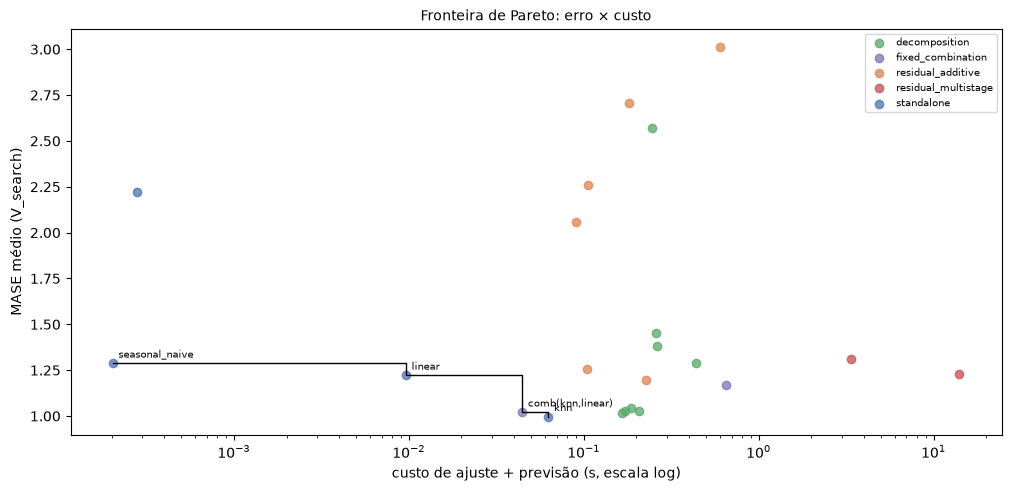

In [9]:
result.plot("pareto")

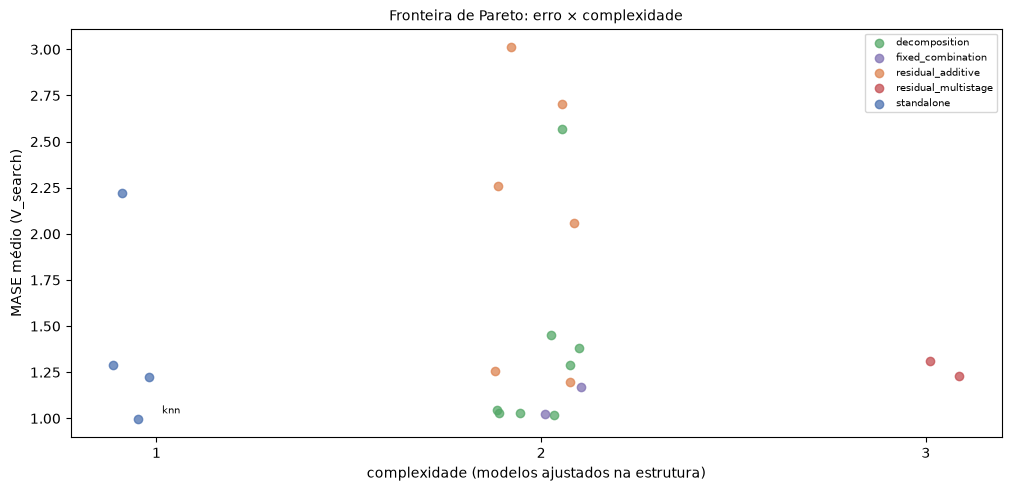

In [10]:
result.plot("pareto", x="complexity")

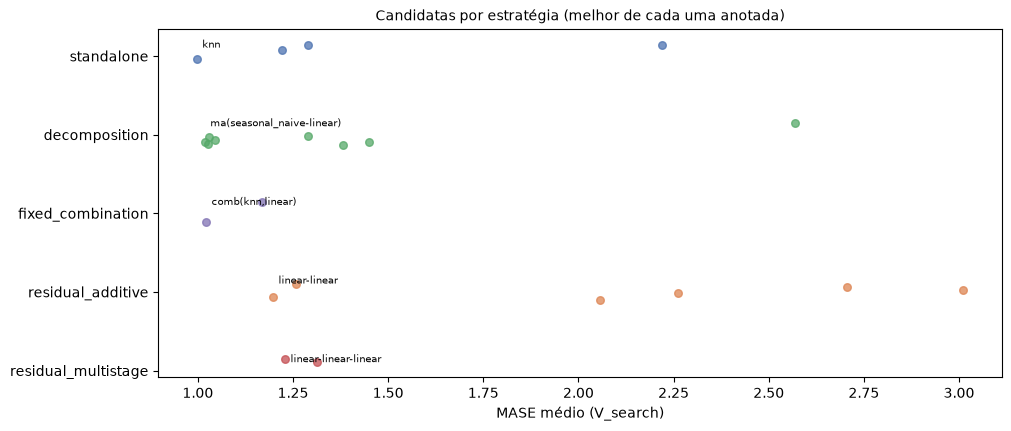

In [11]:
result.plot("strategies")

In [12]:
table = result.strategy_table()
table[table["pareto_cost"]][["name", "strategy", "score", "cost_seconds", "complexity"]]

,name,strategy,score,cost_seconds,complexity
0,knn,standalone,0.997024,0.062906,1
2,"comb(knn,linear)",fixed_combination,1.021385,0.044596,2
8,linear,standalone,1.222285,0.009647,1
11,seasonal_naive,standalone,1.288067,0.000204,1


## 5. Hyperparameter tuning

`tune_model` samples configurations of the base (Optuna/TPE if the `optuna` extra is installed; otherwise a seeded random search) and scores each one on `V_search` only. The original configuration is trial 0, so the result is never worse than it on that layer. The tuned model's `V_select` was not seen by the tuning: compare there.

In [13]:
tuned, tuner = exp.tune_model("knn", n_trials=15, return_tuner=True)
print(
    tuner.sampler,
    "| best:",
    tuner.best.label,
    "| gain on V_search:",
    round(tuner.improvement, 3),
)
tuner.trials.sort_values("score").head()

optuna | best: knn(estimator_params={'n_neighbors': 4}, lags=9) | gain on V_search: 0.07


,candidate_id,label,score,coverage,lags,estimator_params.n_neighbors
trial,,,,,,
9,f13455bf5d4c7c2fe3848bc69fda2d605c31ec84a72a04...,"knn(estimator_params={'n_neighbors': 4}, lags=9)",0.927339,1.0,9,4.0
12,b2507bfe6a5a5139cee8592ba25adbae126ecdfdb50935...,"knn(estimator_params={'n_neighbors': 16}, lags...",0.945013,1.0,28,16.0
14,825b4918ea827459fa3f70c23a4a2b24ae5cf89e3aa220...,"knn(estimator_params={'n_neighbors': 19}, lags...",0.981068,1.0,26,19.0
0,70ad174e1cc49eb256646399fb3e4b7d9df82f14f2978d...,knn(lags=7),0.997024,1.0,7,NaN
4,d3d11c72bb17bcf92dff9a1ebe27c65a49485371e83a56...,"knn(estimator_params={'n_neighbors': 14}, lags...",1.003079,1.0,20,14.0


In [14]:
original = exp.create_model("knn", lags=7)
pd.DataFrame(
    {
        "original": original.evaluation.to_frame().groupby("layer")["MASE"].mean(),
        "tuned": tuned.evaluation.to_frame().groupby("layer")["MASE"].mean(),
    }
)

,original,tuned
layer,,
search,0.997024,0.927339
select,1.826936,1.864958


Custom space: `(minimum, maximum)` for ranges, a list for choices, dotted names for estimator parameters.

In [15]:
exp.tune_model(
    "svm",
    n_trials=6,
    search_space={
        "lags": (7, 21),
        "estimator_params.C": (0.1, 10.0),
        "estimator_params.epsilon": [0.01, 0.1],
    },
)

ModelResult('svm(lags=7)')